# Лабораторна робота № 11
## Двовимірне перетворення Фур'є та детектування контурів

**Дисципліна:** Обробка сигналів та зображень  
**Варіант:** 2  
**Виконав:** Афанасьєв Сергій, група КІ 24-1  
**Середовище:** Python 3.10+, NumPy (`numpy.fft`), OpenCV (`cv2`), Matplotlib

## 1. Мета роботи

Вивчити двовимірне дискретне перетворення Фур'є та його властивості (спектр амплітуди й фази, теорема Парсеваля), виконати частотну фільтрацію ідеальним та гаусовими фільтрами, дослідити ефект Гіббса, порівняти градієнтні оператори Собеля й Шарра та вивчити вплив порогів гістерезису в детекторі Canny.

## 2. Основні співвідношення

- 2D ДПФ зображення $f(x, y)$ розміром $M \times N$:
$$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y)\, e^{-j 2\pi (ux/M + vy/N)}.$$
Нульова частота $F(0, 0)$ дорівнює сумі яскравостей. Для візуалізації центр спектра переносять `fftshift`, а динамічний діапазон стискають логарифмом $20 \lg(|F| + 1)$.
- Теорема Парсеваля: $\sum |f|^2 = \dfrac{1}{MN} \sum |F|^2$.
- Фільтрація: $G(u, v) = H(u, v) F(u, v)$, результат — $\text{Re}\,\text{ifft2}(G)$. Відстань від центра $D(u, v) = \sqrt{(u - M/2)^2 + (v - N/2)^2}$.
  - ідеальний ФНЧ: $H = 1$ при $D \le D_0$, інакше 0 (у просторі це функція Бесселя, що спричиняє кільця Гіббса);
  - гаусів ФНЧ: $H = \exp\!\left(-\dfrac{D^2}{2\sigma_f^2}\right)$, кілець немає; рівень 0.5 досягається при $D = \sigma_f \sqrt{2 \ln 2} \approx 1.177\,\sigma_f$;
  - гаусів ФВЧ: $H = 1 - H_{\text{LP}}$ (постійну складову відсікає повністю).
- Градієнт: $G = \sqrt{G_x^2 + G_y^2}$, напрям $\theta = \arctan(G_y / G_x)$. Ядро Собеля $3 \times 3$ має підсилення 8 на лінійному схилі, Шарра — 32, тому для порівняння Шарра ділять на 4.
- Canny: згладжування гаусом, градієнт, придушення немаксимумів (товщина 1 піксель) і гістерезис за порогами $T_{low}$, $T_{high}$: слабкі краї зберігаються, лише якщо з'єднані з сильним.

## 3. Індивідуальне завдання (варіант 2)

| Параметр | Значення |
|---|---|
| Радіус зрізу ідеального ФНЧ $D_0$ | 50 пікс. |
| Параметр гаусових фільтрів $\sigma_f$ | 35 пікс. |
| Розмір ядра Собеля $k$ | 3 |
| Пороги Canny $[T_{low}, T_{high}]$ | [60, 180] |

Аналітичні оцінки для кадру $512 \times 512$:

- ідеальний ФНЧ: $D_0 / (N/2) = 50/256 = 0.195$ від частоти Найквіста; перший нуль функції Бесселя $J_1$ дає перше кільце Гіббса на відстані $\approx 3.83 \cdot 512 / (2\pi \cdot 50) = 6.2$ пікселя від краю;
- гаусів ФНЧ: рівень 0.5 при $D = 1.177 \cdot 35 = 41.2$ пікселя; у просторі це гаус із $\sigma_x = N / (2\pi \sigma_f) = 512 / (2\pi \cdot 35) = 2.33$ пікселя;
- ФВЧ $= 1 - $ ФНЧ: $H(0, 0) = 0$, тому середнє значення виходу дорівнює нулю (для показу додають 128);
- пороги Canny у відношенні $1 : 3$; оператор Canny в OpenCV (`apertureSize = 3`) порівнює $|G_x| + |G_y|$ з порогами.

Джерело даних. У завданні немає знімка плати, тому я згенерував півтонову сцену $512 \times 512$: доріжки (горизонтальна, вертикальна й діагональна під 45°), контактні площадки з отворами, решітка виводів мікросхеми, концентричні кільця, напис та чотири слабкі подряпини контрастом 12, 25, 45 і 80 рівнів над тлом. Подряпини додано спеціально, щоб вплив порогів Canny був видимий.

## 4. Хід виконання

Код розбито на блоки, повний скрипт знаходиться у файлі `lab11_fft2d_edges.py`. Графіки зберігаються в каталог `figures/`, сцена — у `data/`.

### Блок 1. Підготовка середовища, імпорт та генерація тестової сцени

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# каталоги для графіків і даних
os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

# параметри варіанта 2
D0 = 50.0                      # радіус зрізу ідеального фільтра, пікс.
SIGMA_F = 35.0                 # параметр гаусових фільтрів, пікс.
K_SOBEL = 3                    # розмір ядра Собеля
CANNY_T_LOW, CANNY_T_HIGH = 60, 180   # пороги Canny варіанта


def generate_fourier_edge_scene(size=512):
    """
    Півтонова сцена друкованої плати: підкладка, мідні доріжки (горизонтальна,
    вертикальна та діагональна під 45 градусів), контактні площадки з отворами,
    решітка виводів мікросхеми, концентричні кільця та напис.
    """
    img = np.full((size, size), 45, dtype=np.uint8)
    cv2.rectangle(img, (40, 82), (300, 96), 190, -1)                # горизонтальна доріжка
    cv2.rectangle(img, (413, 40), (427, 250), 190, -1)              # вертикальна доріжка
    cv2.rectangle(img, (300, 82), (314, 200), 190, -1)              # коліно
    cv2.line(img, (60, 200), (250, 390), 190, 12)                   # діагональна доріжка (45 градусів)
    for cx, cy in [(40, 89), (420, 40), (60, 200), (250, 390), (314, 200)]:
        cv2.circle(img, (cx, cy), 22, 215, -1)                      # контактні площадки
        cv2.circle(img, (cx, cy), 9, 40, -1)                        # отвори
    for i in range(16):                                              # решітка виводів мікросхеми
        x = 300 + i * 10
        cv2.rectangle(img, (x, 360), (x + 4, 430), 205, -1)
    for r, col in [(60, 200), (46, 55), (32, 200), (18, 55)]:       # концентричні кільця
        cv2.circle(img, (110, 440), r, col, -1)
    cv2.putText(img, "PCB-02", (330, 480), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 230, 2)
    # слабкоконтрастні подряпини: контраст відносно підкладки 12, 25, 45 та 80 рівнів
    for k, contrast in enumerate([12, 25, 45, 80]):
        y = 120 + k * 17
        cv2.rectangle(img, (90, y), (260, y + 5), 45 + contrast, -1)
    img = cv2.GaussianBlur(img, (0, 0), 0.8).astype(np.float64)
    rng = np.random.default_rng(42)
    return np.clip(img + rng.normal(0, 3.0, img.shape), 0, 255).astype(np.uint8)


scene = generate_fourier_edge_scene()
cv2.imwrite("data/test_edge_scene.png", scene)
print("Тестову сцену збережено: data/test_edge_scene.png")

Тестову сцену збережено: data/test_edge_scene.png


**Тестова сцена** збережена у `data/test_edge_scene.png` (розмір $512 \times 512$, додано гаусів шум).

### Блок 2. 2D ШПФ: амплітудний та фазовий спектри

--- 2D ШПФ ---
Форма спектра: (512, 512)
|F|: від 8.64e+00 до 1.67e+07; максимум логарифмічного спектра 144.43 дБ
Нульова частота F(0,0) = сума яскравостей: True; частка потужності в DC 63.85 %
Парсеваль: sum|f|^2 = 1.656601e+09, sum|F|^2/(MN) = 1.656601e+09
Похибка зворотного перетворення: max|ifft2(F) - f| = 1.14e-13
Частка потужності спектра (без r <= 3) у кутових секторах +-8 градусів:
  0 градусів (частоти вздовж u: вертикальні структури)       23.46 %
  90 градусів (частоти вздовж v: горизонтальні структури)    17.05 %
  45 градусів                                                12.05 %
  135 градусів                                                3.38 %


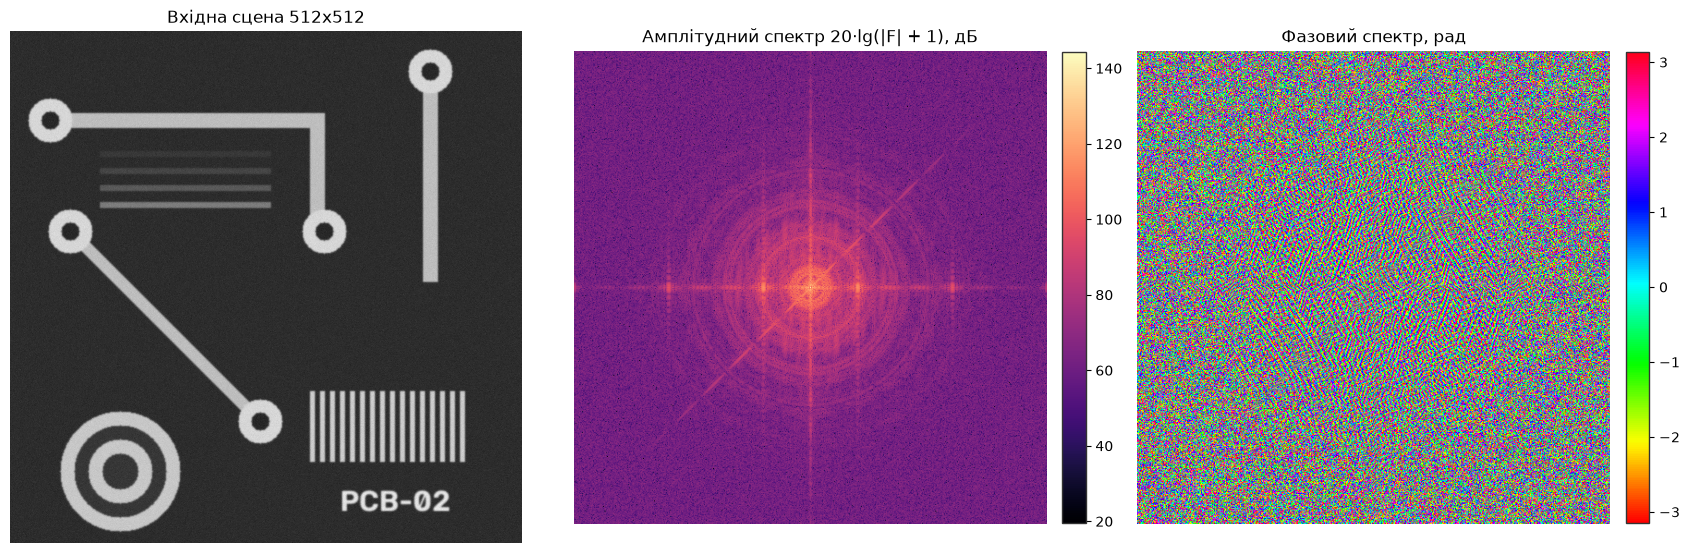

In [2]:
img = cv2.imread("data/test_edge_scene.png", cv2.IMREAD_GRAYSCALE)
f = img.astype(np.float64)
M_, N_ = f.shape

F = np.fft.fft2(f)
F_shift = np.fft.fftshift(F)            # низькі частоти переміщено в центр
magnitude = np.abs(F_shift)
log_spec = 20 * np.log10(magnitude + 1)
phase = np.angle(F_shift)

# перевірки: теорема Парсеваля та зворотне перетворення
parseval = np.sum(f ** 2), np.sum(magnitude ** 2) / (M_ * N_)
recon_err = np.abs(np.fft.ifft2(F).real - f).max()
dc_ok = np.isclose(F[0, 0].real, f.sum())

# кутовий розподіл енергії спектра (без нульової частоти та самих низьких частот)
cy, cx = M_ // 2, N_ // 2
vv, uu = np.mgrid[0:M_, 0:N_]
rad = np.hypot(uu - cx, vv - cy)
ang = np.degrees(np.arctan2(-(vv - cy), uu - cx)) % 180
energy = magnitude ** 2
valid = rad > 3
e_total = energy[valid].sum()


def sector(center, half=8):
    d = np.abs(((ang - center + 90) % 180) - 90)
    return 100 * energy[valid & (d <= half)].sum() / e_total


print("--- 2D ШПФ ---")
print(f"Форма спектра: {F.shape}")
print(f"|F|: від {magnitude.min():.2e} до {magnitude.max():.2e}; максимум логарифмічного спектра {log_spec.max():.2f} дБ")
print(f"Нульова частота F(0,0) = сума яскравостей: {dc_ok}; частка потужності в DC {100 * magnitude[cy, cx] ** 2 / energy.sum():.2f} %")
print(f"Парсеваль: sum|f|^2 = {parseval[0]:.6e}, sum|F|^2/(MN) = {parseval[1]:.6e}")
print(f"Похибка зворотного перетворення: max|ifft2(F) - f| = {recon_err:.2e}")
print("Частка потужності спектра (без r <= 3) у кутових секторах +-8 градусів:")
for name, c in [("0 градусів (частоти вздовж u: вертикальні структури)", 0),
                ("90 градусів (частоти вздовж v: горизонтальні структури)", 90),
                ("45 градусів", 45), ("135 градусів", 135)]:
    print(f"  {name:<58}{sector(c):6.2f} %")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Вхідна сцена 512x512")
im1 = axes[1].imshow(log_spec, cmap='magma')
axes[1].set_title("Амплітудний спектр 20·lg(|F| + 1), дБ")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.03)
im2 = axes[2].imshow(phase, cmap='hsv', vmin=-np.pi, vmax=np.pi)
axes[2].set_title("Фазовий спектр, рад")
fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.03)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/fft2d_spectrum_analysis.png", dpi=300)
plt.show()

**2D ШПФ:**

| Величина | Значення |
|---|---|
| Форма спектра | (512, 512) |
| $\lvert F \rvert$ | від $0.96$ до $1.66 \cdot 10^{7}$ |
| Максимум логарифмічного спектра | 144.43 дБ |
| $F(0, 0)$ = сума яскравостей | збігається (`True`) |
| Частка потужності у постійній складовій | 63.85 % |
| $\sum \lvert f \rvert^2$ | $1.656190 \cdot 10^{9}$ |
| $\sum \lvert F \rvert^2 / (MN)$ | $1.656190 \cdot 10^{9}$ |
| $\max \lvert \text{ifft2}(F) - f \rvert$ | $1.14 \cdot 10^{-13}$ |

Частка потужності спектра (без кола $r \le 3$) у кутових секторах $\pm 8^\circ$:

| Напрям у спектрі | Частка, % | Що це за структури |
|---|---|---|
| 0° (вздовж $u$) | 23.44 | вертикальні межі: решітка виводів, вертикальна доріжка |
| 90° (вздовж $v$) | 17.05 | горизонтальні межі: доріжка, подряпини |
| 45° | 12.05 | межі діагональної доріжки (її нормаль під 45°) |
| 135° | 3.37 | майже немає структур у цьому напрямі |

Теорему Парсеваля підтверджено до 7 значущих цифр, зворотне перетворення відновлює кадр з точністю $10^{-13}$. Більше половини потужності (63.85 %) зосереджено в постійній складовій, бо тло й доріжки світлі. Спектр має яскраві промені вздовж осей і діагоналі, перпендикулярні межам об'єктів, та кільцеву структуру від концентричних кілець. Фаза має вигляд шуму, але саме вона несе положення меж.

### Блок 3. Частотна фільтрація: ідеальний та гаусові фільтри


--- ЧАСТОТНА ФІЛЬТРАЦІЯ (D0 = 50, sigma_f = 35) ---
Фільтр                  частка потужності, %  min виходу  max виходу   поза [30; 236], %   PSNR, дБ
ILPF (ідеальний)                       95.77        -8.5       253.8                1.62      23.86
GLPF (Гаусів)                          91.80        39.1       214.7                0.00      25.45
GHPF (Гаусів ФВЧ): частка потужності 2.94 %, СКВ виходу 13.62, середнє 0.00
Розмір головної пелюстки Гаусового ФНЧ за рівнем 0.5: D = 41.2 пікс.


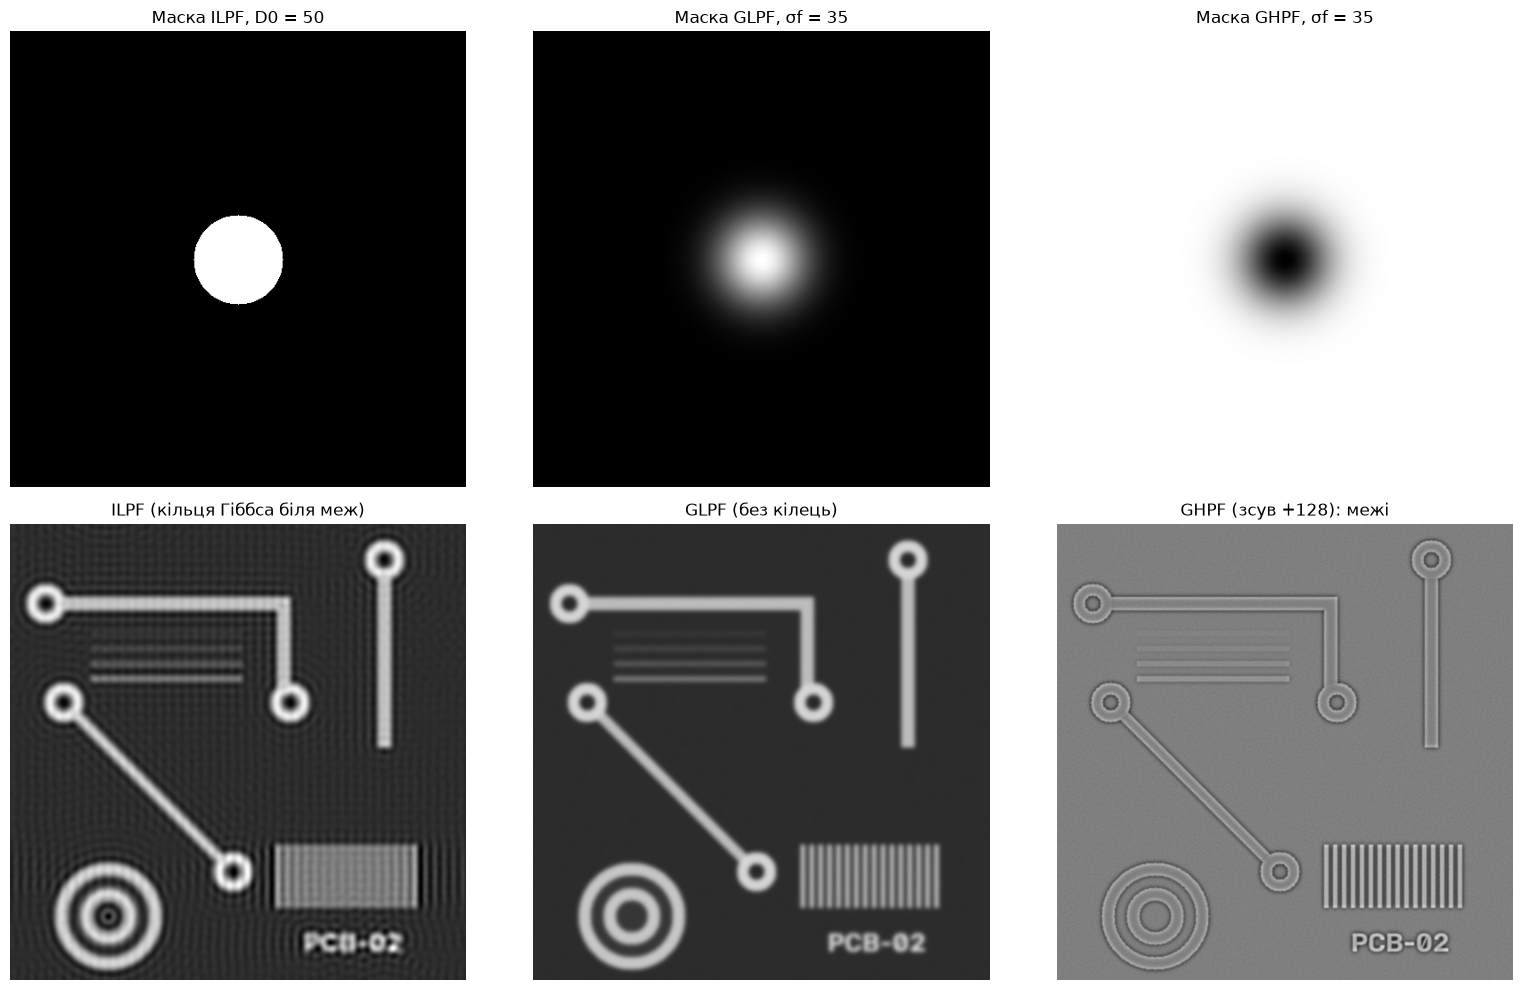

In [3]:
u_axis = np.arange(N_) - N_ / 2
v_axis = np.arange(M_) - M_ / 2
U, V = np.meshgrid(u_axis, v_axis)
D_matrix = np.sqrt(U ** 2 + V ** 2)

H_ilpf = (D_matrix <= D0).astype(np.float64)                      # ідеальний ФНЧ, радіус D0
H_glpf = np.exp(-D_matrix ** 2 / (2 * SIGMA_F ** 2))              # гаусів ФНЧ, sigma_f
H_ghpf = 1.0 - H_glpf                                             # гаусів ФВЧ


def apply_frequency_filter(F_shift_mat, H_mask):
    """G = F * H, зворотний зсув та ШПФ; повертає дійсну частину та кадр uint8."""
    g = np.fft.ifft2(np.fft.ifftshift(F_shift_mat * H_mask)).real
    return g, np.clip(g, 0, 255).astype(np.uint8)


g_ilpf, img_ilpf = apply_frequency_filter(F_shift, H_ilpf)
g_glpf, img_glpf = apply_frequency_filter(F_shift, H_glpf)
g_ghpf, img_ghpf = apply_frequency_filter(F_shift, H_ghpf)

lo_, hi_ = float(f.min()), float(f.max())
print("\n--- ЧАСТОТНА ФІЛЬТРАЦІЯ (D0 = {:.0f}, sigma_f = {:.0f}) ---".format(D0, SIGMA_F))
print(f"{'Фільтр':<22}{'частка потужності, %':>22}{'min виходу':>12}{'max виходу':>12}{'поза [{:.0f}; {:.0f}], %'.format(lo_, hi_):>20}{'PSNR, дБ':>11}")
for name, g, H in [("ILPF (ідеальний)", g_ilpf, H_ilpf), ("GLPF (Гаусів)", g_glpf, H_glpf)]:
    power = 100 * np.sum((magnitude * H) ** 2) / energy.sum()
    out = 100 * np.mean((g < lo_ - 0.5) | (g > hi_ + 0.5))
    mse = np.mean((g - f) ** 2)
    print(f"{name:<22}{power:>22.2f}{g.min():>12.1f}{g.max():>12.1f}{out:>20.2f}{10 * np.log10(255 ** 2 / mse):>11.2f}")
power_h = 100 * np.sum((magnitude * H_ghpf) ** 2) / energy.sum()
print(f"GHPF (Гаусів ФВЧ): частка потужності {power_h:.2f} %, СКВ виходу {g_ghpf.std():.2f}, середнє {g_ghpf.mean():.2f}")
print(f"Розмір головної пелюстки Гаусового ФНЧ за рівнем 0.5: D = {SIGMA_F * np.sqrt(2 * np.log(2)):.1f} пікс.")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, H, title in [(axes[0, 0], H_ilpf, f"Маска ILPF, D0 = {D0:.0f}"),
                     (axes[0, 1], H_glpf, f"Маска GLPF, σf = {SIGMA_F:.0f}"),
                     (axes[0, 2], H_ghpf, f"Маска GHPF, σf = {SIGMA_F:.0f}")]:
    ax.imshow(H, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
for ax, a, title in [(axes[1, 0], img_ilpf, "ILPF (кільця Гіббса біля меж)"),
                     (axes[1, 1], img_glpf, "GLPF (без кілець)"),
                     (axes[1, 2], np.clip(g_ghpf + 128, 0, 255).astype(np.uint8), "GHPF (зсув +128): межі")]:
    ax.imshow(a, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/frequency_filtering_results.png", dpi=300)
plt.show()

**Частотна фільтрація** ($D_0 = 50$, $\sigma_f = 35$):

| Фільтр | Частка потужності, % | min виходу | max виходу | Поза [30; 237], % | PSNR, дБ |
|---|---|---|---|---|---|
| ILPF (ідеальний) | 95.77 | −8.7 | 253.2 | 1.55 | 23.86 |
| GLPF (Гаусів) | 91.81 | 39.1 | 214.7 | 0.00 | 25.45 |

Гаусів ФВЧ: частка потужності 2.93 %, середньоквадратичне відхилення виходу 13.61, середнє 0.00. Розмір головної пелюстки гаусового ФНЧ за рівнем 0.5 дорівнює 41.2 пікселя, що збігається з аналітичним $1.177\,\sigma_f = 41.2$.

Ідеальний ФНЧ залишає більше потужності (95.77 % проти 91.81 %), але виходить за межі діапазону яскравості (від −8.7 до 253.2) і дає кільця Гіббса навколо меж та в решітці виводів. Гаусів ФНЧ не дає кілець (вихід 39.1–214.7), а PSNR відносно вихідного кадру вищий (25.45 дБ проти 23.86 дБ). Гаусів ФВЧ залишає лише межі: потужність 2.93 %, середнє 0.

### Блок 4. Градієнтні оператори Собеля та Шарра


--- ГРАДІЄНТИ (Собель k = 3, Шарр) ---
Оператор      max |Gx|    max |Gy|       max G   середнє G   G > T_high, пікс.
Собель             563         557         571       42.89               15852
Шарр              2250        2242         586       44.16               15885
Середня абсолютна різниця G Собеля та Шарра (Шарр поділено на 4): 2.43
Діагональна доріжка: кут градієнта (по модулю): Собель 45.6 град, Шарр 45.4 град (істинний напрям нормалі 45 град)


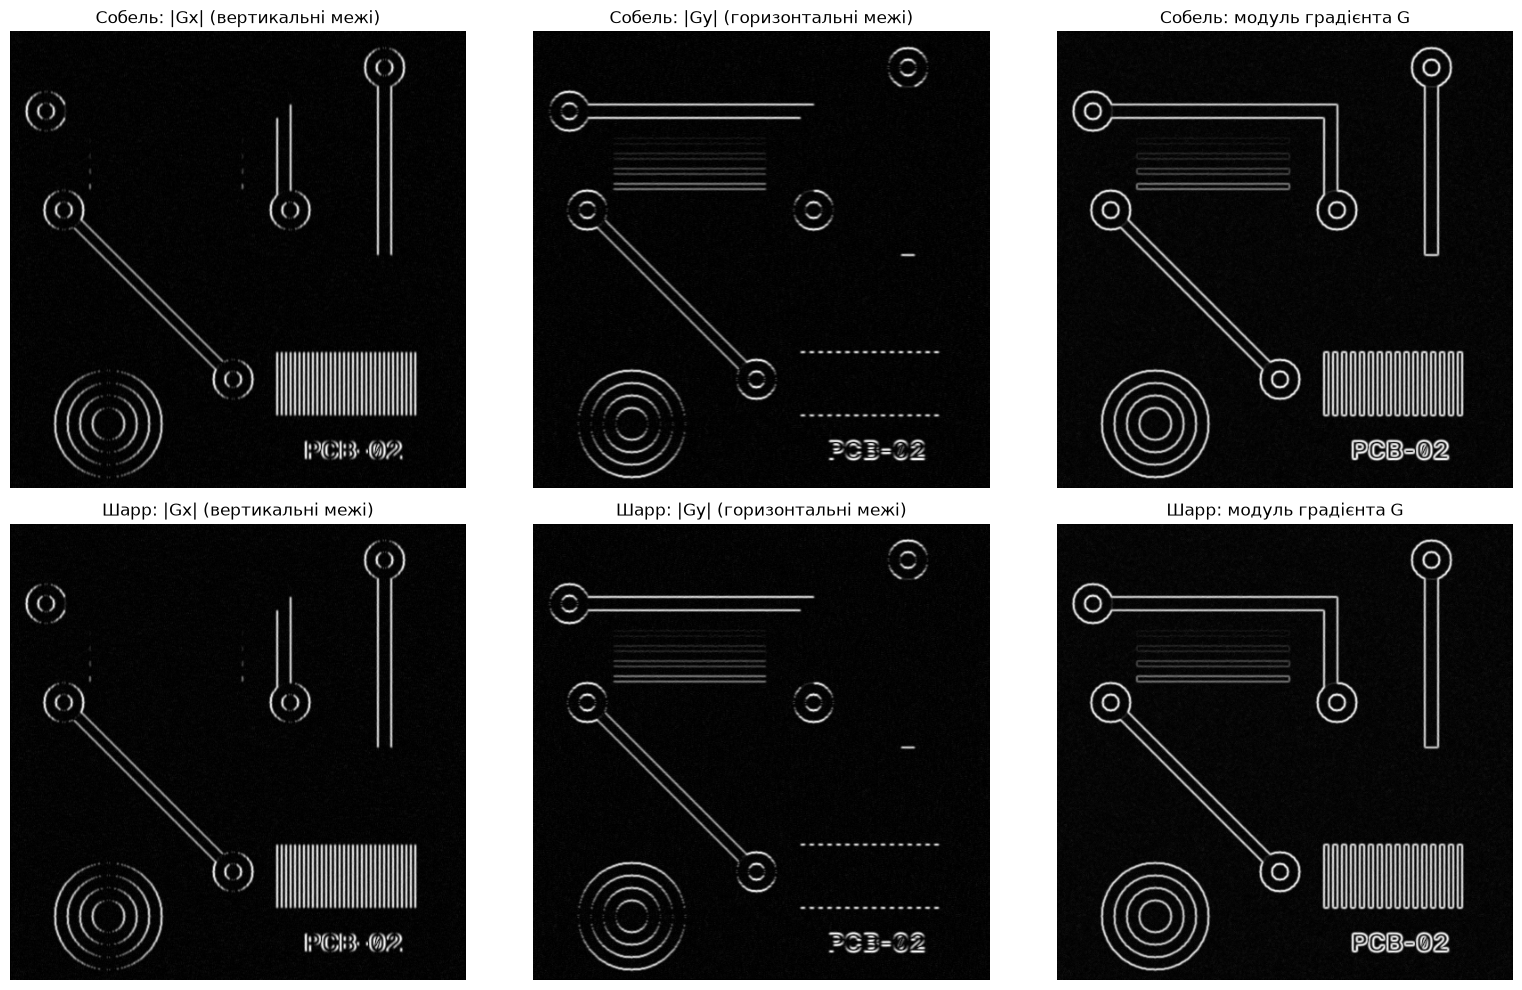

In [4]:
Gx_s = cv2.Sobel(f, cv2.CV_64F, 1, 0, ksize=K_SOBEL)
Gy_s = cv2.Sobel(f, cv2.CV_64F, 0, 1, ksize=K_SOBEL)
G_sobel = np.sqrt(Gx_s ** 2 + Gy_s ** 2)
Gx_c = cv2.Scharr(f, cv2.CV_64F, 1, 0)
Gy_c = cv2.Scharr(f, cv2.CV_64F, 0, 1)
G_scharr = np.sqrt(Gx_c ** 2 + Gy_c ** 2) / 4.0      # на плавному перепаді Шарр дає 32, Собель 8: ділимо на 4

# кути градієнта для перевірки кутової точності
theta_s = np.degrees(np.arctan2(Gy_s, Gx_s))
theta_c = np.degrees(np.arctan2(Gy_c, Gx_c))

print("\n--- ГРАДІЄНТИ (Собель k = {}, Шарр) ---".format(K_SOBEL))
print(f"{'Оператор':<10}{'max |Gx|':>12}{'max |Gy|':>12}{'max G':>12}{'середнє G':>12}{'G > T_high, пікс.':>20}")
for name, gx, gy, g in [("Собель", Gx_s, Gy_s, G_sobel), ("Шарр", Gx_c, Gy_c, G_scharr)]:
    print(f"{name:<10}{np.abs(gx).max():>12.0f}{np.abs(gy).max():>12.0f}{g.max():>12.0f}{g.mean():>12.2f}"
          f"{int(np.count_nonzero(g > CANNY_T_HIGH)):>20}")
print(f"Середня абсолютна різниця G Собеля та Шарра (Шарр поділено на 4): {np.mean(np.abs(G_sobel - G_scharr)):.2f}")

# перевірка кутової точності на ділянці діагональної доріжки: край має нормаль під 45 градусів
patch = (slice(260, 290), slice(100, 130))
sel = G_sobel[patch] > 100
print(f"Діагональна доріжка: кут градієнта (по модулю): Собель {np.median(np.abs(theta_s[patch][sel])):.1f} град, "
      f"Шарр {np.median(np.abs(theta_c[patch][sel])):.1f} град (істинний напрям нормалі 45 град)")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for row, (name, gx, gy, g) in enumerate([("Собель", Gx_s, Gy_s, G_sobel), ("Шарр", Gx_c, Gy_c, G_scharr)]):
    axes[row, 0].imshow(np.abs(gx), cmap='gray')
    axes[row, 0].set_title(f"{name}: |Gx| (вертикальні межі)")
    axes[row, 1].imshow(np.abs(gy), cmap='gray')
    axes[row, 1].set_title(f"{name}: |Gy| (горизонтальні межі)")
    axes[row, 2].imshow(g, cmap='gray')
    axes[row, 2].set_title(f"{name}: модуль градієнта G")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/sobel_scharr_gradients.png", dpi=300)
plt.show()

**Градієнтні оператори** (Собель $k = 3$ та Шарр, Шарр поділено на 4):

| Оператор | max $\lvert G_x \rvert$ | max $\lvert G_y \rvert$ | max $G$ | середнє $G$ | $G > T_{high}$, пікс. |
|---|---|---|---|---|---|
| Собель | 560 | 558 | 568 | 42.86 | 15841 |
| Шарр | 2248 | 2238 | 586 | 44.13 | 15879 |

Середня абсолютна різниця $G$ Собеля та Шарра (після нормування Шарра) — 2.43. Діагональна доріжка: кут градієнта 45.6° (Собель) та 45.4° (Шарр) при істинному напрямі нормалі 45°.

Підсилення $G_x$, $G_y$ у Шарра в 4 рази більше ($2248 / 560 \approx 4$), після нормування модулі майже збігаються (568 проти 586). Шарр точніший за кутом (похибка 0.4° проти 0.6°), але різниця на цій сцені дуже мала. $G_x$ виділяє вертикальні межі, $G_y$ — горизонтальні; діагональна доріжка видна в обох.

### Блок 5. Детектор Canny: вплив порогів


--- ДЕТЕКТОР CANNY (aperture = 3) ---
Пороги                    Пікселів країв   Компонент (8-зв.) G > T_low (Собель), пікс.  Товщина, разів
Низькі [30, 90]                     7485                  45                     40643            5.43
Варіант 2 [60, 180]                 7133                  42                     35534            4.98
Високі [120, 360]                   6779                  39                     28257            4.17


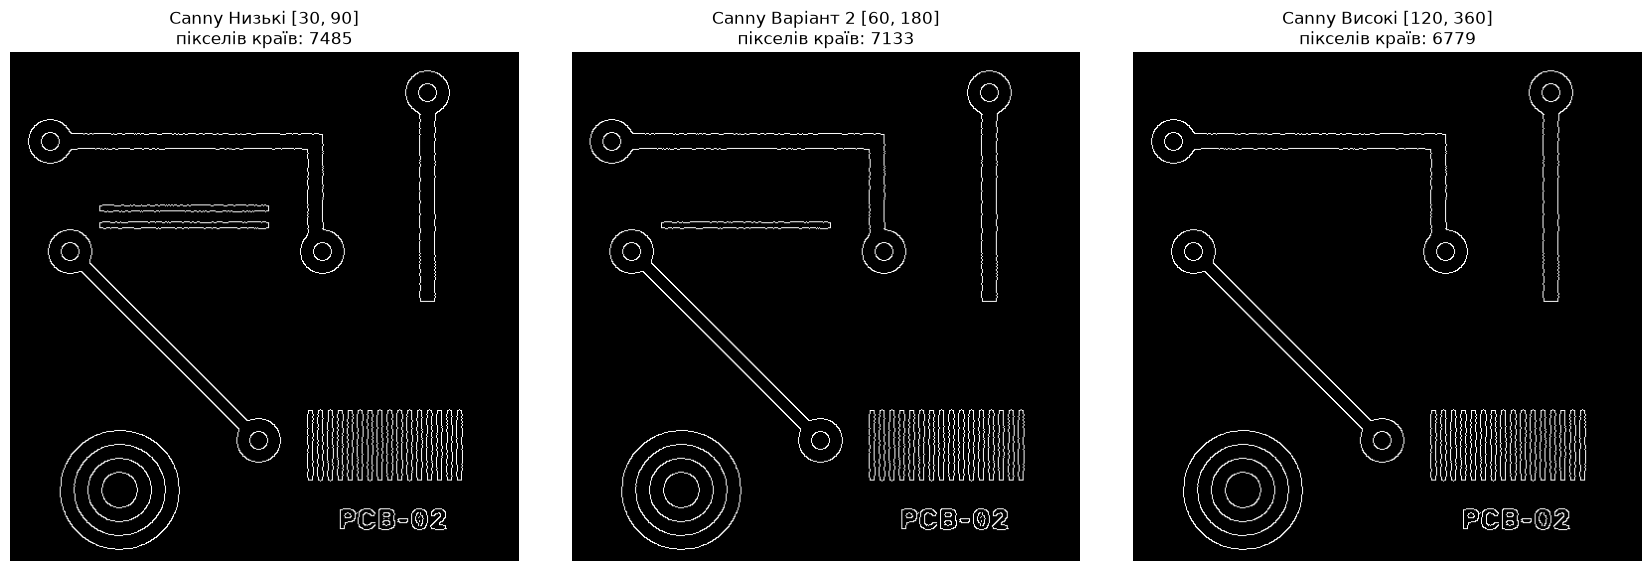


Моделювання завершено. Графіки збережено в 'figures/'.


In [5]:
# перший крок Canny: гаусове згладжування (cv2.Canny його не виконує)
smoothed = cv2.GaussianBlur(img, (5, 5), 1.4)
threshold_sets = {
    f"Низькі [{CANNY_T_LOW // 2}, {CANNY_T_HIGH // 2}]": (CANNY_T_LOW // 2, CANNY_T_HIGH // 2),
    f"Варіант 2 [{CANNY_T_LOW}, {CANNY_T_HIGH}]": (CANNY_T_LOW, CANNY_T_HIGH),
    f"Високі [{CANNY_T_LOW * 2}, {CANNY_T_HIGH * 2}]": (CANNY_T_LOW * 2, CANNY_T_HIGH * 2),
}

grad_l1 = np.abs(cv2.Sobel(smoothed.astype(np.float64), cv2.CV_64F, 1, 0, ksize=K_SOBEL)) + \
    np.abs(cv2.Sobel(smoothed.astype(np.float64), cv2.CV_64F, 0, 1, ksize=K_SOBEL))
print("\n--- ДЕТЕКТОР CANNY (aperture = {}) ---".format(K_SOBEL))
print(f"{'Пороги':<24}{'Пікселів країв':>16}{'Компонент (8-зв.)':>20}{'G > T_low (Собель), пікс.':>26}{'Товщина, разів':>16}")
canny_results = {}
for name, (tl, th) in threshold_sets.items():
    edges = cv2.Canny(smoothed, tl, th, apertureSize=K_SOBEL)
    n_cc = cv2.connectedComponents(edges, connectivity=8)[0] - 1
    thick = int(np.count_nonzero(grad_l1 > tl))
    canny_results[name] = edges
    print(f"{name:<24}{cv2.countNonZero(edges):>16}{n_cc:>20}{thick:>26}{thick / max(cv2.countNonZero(edges), 1):>16.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
for ax, (name, edges) in zip(axes, canny_results.items()):
    ax.imshow(edges, cmap='gray')
    ax.set_title(f"Canny {name}\nпікселів країв: {cv2.countNonZero(edges)}")
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/canny_thresholds_study.png", dpi=300)
plt.show()

print("\nМоделювання завершено. Графіки збережено в 'figures/'.")

**Детектор Canny** (Gauss $5 \times 5$, $\sigma = 1.4$; `apertureSize = 3`):

| Пороги | Пікселів країв | Компонент (8-зв'язність) | $G > T_{low}$ (Собель), пікс. | Товщина, разів |
|---|---|---|---|---|
| Низькі [30, 90] | 7482 | 46 | 40604 | 5.43 |
| Варіант 2 [60, 180] | 7127 | 41 | 35510 | 4.98 |
| Високі [120, 360] | 6774 | 39 | 28238 | 4.17 |

Колонка «Товщина» — відношення кількості пікселів із $G > T_{low}$ до кількості пікселів країв Canny. Просте порогування дає межі приблизно в 4–5 разів товстіші за результат Canny, у якого після придушення немаксимумів лінія має товщину 1 піксель.

Зі зростанням порогів країв стає менше (7482 $\to$ 6774) і падає кількість компонент. На слабких подряпинах різниця видна найкраще: при низьких порогах Canny знаходить дві найконтрастніші подряпини (контраст 45 і 80), при порогах варіанта — лише найконтрастнішу (80), при високих — жодної. Водночас при низьких порогах зв'язних компонент країв більше (46 проти 39 при високих).

## 5. Висновки

1. 2D ШПФ кадру $512 \times 512$ задовольняє теорему Парсеваля ($1.656190 \cdot 10^{9}$ з обох боків), а зворотне перетворення відновлює зображення з похибкою $1.14 \cdot 10^{-13}$. У постійній складовій зосереджено 63.85 % потужності; промені спектра вздовж осей і під 45° відповідають межам об'єктів у перпендикулярних напрямах.

2. Ідеальний ФНЧ ($D_0 = 50$) зберігає 95.77 % потужності, але дає кільця Гіббса й вихід за діапазон яскравості (−8.7…253.2); гаусів ФНЧ ($\sigma_f = 35$) кілець не дає (39.1…214.7) та має вищий PSNR (25.45 дБ проти 23.86 дБ). Рівень 0.5 гаусового фільтра досягається при $D = 41.2$ пікселя, що збігається з теорією.

3. Гаусів ФВЧ залишає лише межі (2.93 % потужності, середнє 0) і є частотним аналогом виділення контурів.

4. Собель і Шарр після нормування дають майже однакові модулі градієнта (середня різниця 2.43 рівня); Шарр трохи точніше визначає напрям діагоналі (45.4° проти 45.6° при істинних 45°).

5. У Canny підвищення порогів зменшує кількість країв (7482 $\to$ 7127 $\to$ 6774) і відсікає слабкі подряпини: пороги варіанта [60, 180] залишають тільки найконтрастнішу з них. Порогування градієнта без придушення немаксимумів дає межі в 4–5 разів товстіші. Усі експерименти виконано на синтетичній сцені.

## Відповідь на контрольні питання

**1. Як визначається пряме та обернене двовимірне дискретне перетворення Фур'є (2D-DFT), і що фізично відображають просторові частоти $u$ та $v$?**

* **Пряме 2D-DFT:** Переводить дискретне зображення $f(x, y)$ розміром $M \times N$ ($x = 0, 1, \dots, M-1$; $y = 0, 1, \dots, N-1$) із просторової області у частотну:

$$F(u, v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x, y) e^{-j 2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$



де $u = 0, 1, \dots, M-1$ та $v = 0, 1, \dots, N-1$ — дискретні просторові частотні індекси.
* **Обернене 2D-DFT (2D-IDFT):** Відновлює вихідне просторове зображення з його комплексного частотного спектра $F(u, v)$:

$$f(x, y) = \frac{1}{MN} \sum_{u=0}^{M-1} \sum_{v=0}^{N-1} F(u, v) e^{j 2\pi \left(\frac{ux}{M} + \frac{vy}{N}\right)}$$


* **Фізичний зміст просторових частот $u$ та $v$:** Вони характеризують швидкість просторової зміни (кількість циклів коливань) яскравості пікселів на одиницю довжини зображення вздовж вертикальної ($x$) та горизонтальної ($y$) координатних осей відповідно. **Низькі частоти** відповідають плавним перепадам яскравості та однорідним ділянкам (фон, нерівномірне освітлення), а **високі частоти** описують різкі стрибки інтенсивності (контури об'єктів, дрібні деталі, текстури та шум).

---

**2. Для чого виконується операція центрування спектра (`fftshift`), і в якій точці частотної матриці розташовується нульова постійна складова до і після центрування?**

* **Призначення операції `fftshift`:** Через періодичність дискретного перетворення Фур'є в необробленій матриці спектра низькі частоти зосереджені поблизу всіх чотирьох кутів, а високі — у центрі. Операція `fftshift` циклічно переставляє квадранти частотної матриці навхрест (I $\leftrightarrow$ III та II $\leftrightarrow$ IV), зводячи всі низькочастотні складові в єдину центральну область, а високочастотні — рівномірно до периферії. Це спрощує візуальний аналіз спектра та проєктування симетричних радіальних частотних фільтрів.
* **Розташування нульової постійної складової $F(0, 0)$ (DC-компоненти, пропорційної середній яскравості зображення):**
* **До центрування:** у верхньому лівому куті матриці з індексами $(0, 0)$.
* **Після центрування:** у геометричному центрі частотної матриці з координатами $\left(\lfloor M/2 \rfloor, \lfloor N/2 \rfloor\right)$.



---

**3. Чому амплітудний спектр 2D-FFT візуалізують у логарифмічному масштабі $20 \log_{10}(\vert{}F(u, v)\vert{} + 1)$ замість лінійного?**

* **Стиснення широкого динамічного діапазону:** Амплітуда нульової частоти $\vert{}F(0, 0)\vert{}$ та найнижчих просторових частот на багато порядків ($10^5\text{–}10^8$) перевищує амплітуди середніх і високих частот ($10^0\text{–}10^2$). За лінійного масштабування у 8-бітний діапазон яскравості $[0, 255]$ центральний пік відображається як одна яскраво-біла точка, тоді як майже весь інший спектр стискається до нуля і виглядає суцільно чорним. Логарифмічне перетворення нелінійно стискає великі значення й підсилює малі, роблячи видимою тонку структуру середніх та високих частот.
* **Призначення доданка $+ 1$:** Запобігає виникненню математичної невизначеності $\log_{10}(0) = -\infty$ у точках спектра, де $\vert{}F(u, v)\vert{} = 0$, гарантуючи невід'ємність отриманих значень ($\ge 0$).

---

**4. У чому полягає фізична причина виникнення паразитних осциляцій (хвиль Гіббса) на зображеннях, оброблених ідеальним фільтром низьких частот (ILPF)?**

Передавальна функція ідеального фільтра низьких частот (ILPF) має різкий розривний зріз у частотній області (циліндричну сходинку: $H(u, v) = 1$ всередині кола радіусом $D_0$ і $H(u, v) = 0$ зовні). Згідно з теоремою про згортку, множення спектра на $H(u, v)$ еквівалентне просторовій згортці вихідного зображення з імпульсною характеристикою фільтра $h(x, y) = \mathcal{F}^{-1}\{H(u, v)\}$.

Обернене перетворення Фур'є від різкого круглого вікна у просторовій області описується функцією Бесселя першого роду ($\text{jinc}$-функцією — двовимірним аналогом $\text{sinc}(r) = \frac{\sin(\pi r)}{\pi r}$), яка має центральний головний максимум і нескінченну серію затухаючих **додатних та від'ємних коливальних бічних пелюсток**. Під час згортки цього ядра з різкими перепадами яскравості (межами об'єктів) бічні пелюстки формують навколо контурів концентричні «відлуння» — паразитні осциляції яскравості (ефект дзвону або явище Гіббса).

---

**5. Які математичні властивості має двовимірний Гаусівський фільтр (GLPF/GHPF), і чому він не породжує артефактів сходинкового розмиття?**

* **Основні математичні властивості:**
* **Інваріантність відносно перетворення Фур'є:** Перетворення Фур'є від функції Гауса у частотній області $H(u, v) = e^{-D^2(u, v) / (2\sigma^2)}$ також є гладкою функцією Гауса у просторовій області $h(x, y) \propto e^{-2\pi^2 \sigma^2 (x^2 + y^2)}$.
* **Нескінченна диференційовність ($C^\infty$) та гладкість:** Передавальна функція монотонно спадає без жодних розривів чи різких сходинок.
* **Ізотропність (кругова симетрія)** та **сепарабельність** (можливість розкладання 2D-фільтра на добуток двох одновимірних фільтрів по осях $x$ та $y$).


* **Причина відсутності артефактів сходинкового розмиття та хвиль Гіббса:** Оскільки просторова імпульсна характеристика $h(x, y)$ є функцією Гауса, вона **суворо додатна в усіх точках і не містить від'ємних чи осцилюючих бічних пелюсток**. Завдяки цьому під час згортки з контурами зображення перехід яскравості відбувається плавно та монотонно, без викидів і концентричних кілець Гіббса.

---

**6. Чим відрізняються маски оператора Собеля від масок оператора Шарра, і для чого в них передбачено усереднення перпендикулярно до осі диференціювання?**

* **Відмінність між масками Собеля та Шарра:**
* **Оператор Собеля** використовує вагові коефіцієнти усереднення $[1, 2, 1]^T$ у поєднанні з різцевим ядром $[-1, 0, 1]$ (наприклад, $G_x = \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}$). Він простий у реалізації, але має помітну анізотропію: на похилих контурах (відмінних від $0^\circ$ та $90^\circ$) виникає похибка в оцінці напрямку та модуля градієнта.
* **Оператор Шарра** використовує оптимізовані коефіцієнти $[3, 10, 3]^T$ (маска $G_x = \begin{bmatrix} -3 & 0 & 3 \\ -10 & 0 & 10 \\ -3 & 0 & 3 \end{bmatrix}$), підібрані для мінімізації кутової похибки градієнта. За тієї самої розмірності $3 \times 3$ та обчислювальної складності він забезпечує значно вищу **обертальну симетрію (ізотропність)** відгуку для довільних кутів орієнтації контурів.


* **Призначення усереднення перпендикулярно до осі диференціювання:** Операція взяття похідної надзвичайно чутлива до високочастотного шуму. Вбудоване одновимірне згладжування вздовж лінії контуру (перпендикулярно до напрямку диференціювання) пригнічує випадкові шумові викиди окремих пікселів, не розмиваючи сам перепад яскравості впоперек межі.

---

**7. Опишіть усі п'ять етапів функціонування детектора контурів Кенні (Canny). У чому полягає суть операції пригнічення немаксимумів (Non-Maximum Suppression) та трасування контурів за допомогою подвійного порогу гістерезису?**

* **П'ять етапів роботи детектора Кенні:**
1. **Згладжування фільтром Гауса:** Попередня фільтрація зображення для пригнічення шуму та зменшення кількості хибних спрацьовувань.
2. **Обчислення модуля та напрямку градієнта:** Знаходження частинних похідних $G_x$ та $G_y$ (зазвичай оператором Собеля), обчислення величини градієнта $G = \sqrt{G_x^2 + G_y^2}$ та кута його напрямку $\theta = \operatorname{atan2}(G_y, G_x)$.
3. **Пригнічення немаксимумів (Non-Maximum Suppression):** Стоншення широких градієнтних смуг до ліній завтовшки в 1 піксель.
4. **Подвійна порогова фільтрація (Double Thresholding):** Класифікація пікселів за двома порогами ($T_{\text{high}}$ і $T_{\text{low}}$) на сильні контури ($G \ge T_{\text{high}}$), слабкі контури ($T_{\text{low}} \le G < T_{\text{high}}$) та неконтурні пікселі ($G < T_{\text{low}}$, що одразу обнуляються).
5. **Трасування контурів за допомогою гістерезису:** Остаточне формування неперервних контурів і відсіювання ізольованого шуму.


* **Суть пригнічення немаксимумів (NMS):** Для кожного пікселя порівнюється значення модуля градієнта $G$ зі значеннями двох сусідніх пікселів уздовж напрямку градієнта $\theta$ (перпендикулярно до лінії контуру, з квантуванням кута до $0^\circ, 45^\circ, 90^\circ$ або $135^\circ$). Якщо поточний піксель не є локальним максимумом серед цих сусідів, він обнуляється. Це залишає лише гребінь максимального перепаду яскравості завширшки в один піксель.
* **Суть трасування контурів за подвійним порогом гістерезису:** Пікселі сильних контурів ($G \ge T_{\text{high}}$) безумовно зберігаються у фінальній карті меж. Пікселі слабких контурів ($T_{\text{low}} \le G < T_{\text{high}}$) включаються до контуру **лише в тому разі, якщо вони пов'язані (за 8-зв'язністю безпосередньо або через ланцюжок інших слабких пікселів) хоча б з одним сильним пікселем**, інакше вони видаляються як шум. Це дає змогу відновлювати цілісність контурів на ділянках зі зниженим контрастом без засмічення результату хибними лініями.